# Brain MRI Tumor Classification

## Notebook 1 — Dataset Creation and Exploratory Analysis


## Project Overview

This project uses brain MRI images to build an educational four-class image classifier. The classes in the supplied data are **Glioma, Meningioma, No Tumor, and Pituitary**. The image files are already arranged into training, validation, and test folders, and each split has a CSV file with one-hot encoded labels.

In this first notebook, we will connect those existing files into one verified dataset manifest. We will keep the original images and their splits in place; the manifest will record each image path, split, and checked class label. We will also inspect class counts and basic image properties before any model training.

**Use limitation:** this is for learning and experimentation. Model predictions must not be used as medical diagnoses or to guide patient care.


## Notebook Plan

1. Connect Google Drive and set the dataset folder path.
2. Check that the expected `train`, `valid`, and `test` folders, class folders, and CSV files exist.
3. Read each split CSV, find its image file, and create a class label from the one-hot columns.
4. Verify the CSV label against both the image's class folder and its filename class code. Get the split from the folder being processed, not from the filename prefix.
5. Combine the verified rows into one master manifest while preserving the original split.
6. Analyze class counts, label issues, image dimensions, grayscale/RGB modes, and sample images.
7. Save the manifest and analysis outputs to Google Drive.


## Step 1 — Connect Google Drive and set paths

Mount Drive in Colab. Set `DATASET_ROOT` to the folder that directly contains the `train`, `valid`, and `test` folders. For example, if your Drive has `MyDrive/Brain MRI Project/Datasets/train`, then `DATASET_ROOT` should point to `MyDrive/Brain MRI Project/Datasets`.

The path below is a placeholder. Update it after you upload or copy the project dataset to Drive.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pathlib import Path


DATASET_ROOT = Path('/content/drive/MyDrive/Brain MRI Tumor Classification/Datasets')

SPLITS = ('train', 'valid', 'test')
CLASS_FOLDERS = ('glioma', 'meningioma', 'no_tumor', 'pituitary')
CSV_LABEL_COLUMNS = ('Glioma', 'Meningioma', 'No Tumor', 'Pituitary')

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(
        f'Dataset folder not found: {DATASET_ROOT}\n'
        'Edit DATASET_ROOT above so it points to the folder containing train, valid, and test.'
    )
print('Dataset folder:', DATASET_ROOT)


Dataset folder: /content/drive/MyDrive/Brain MRI Tumor Classification/Datasets


## Step 2 — Check the folder structure

Each split should contain the four class folders and a `_classes.csv` file. This check also prints the actual structure we will use. The split value will come from the split folder (`train`, `valid`, or `test`), because filenames in this dataset can begin with `Tr-` even outside the training split.


In [4]:
import os

for split in SPLITS:
    split_dir = DATASET_ROOT / split
    if not split_dir.is_dir():
        raise FileNotFoundError(f'Missing split folder: {split_dir}')
    csv_path = split_dir / '_classes.csv'
    if not csv_path.is_file():
        raise FileNotFoundError(f'Missing labels CSV: {csv_path}')

    actual_classes = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
    print(f'\n{split}:')
    print('  CSV:', csv_path.name)
    print('  class folders:', actual_classes)
    missing_classes = sorted(set(CLASS_FOLDERS) - set(actual_classes))
    extra_classes = sorted(set(actual_classes) - set(CLASS_FOLDERS))
    if missing_classes or extra_classes:
        raise ValueError(f'{split}: missing classes={missing_classes}; unexpected classes={extra_classes}')



train:
  CSV: _classes.csv
  class folders: ['glioma', 'meningioma', 'no_tumor', 'pituitary']

valid:
  CSV: _classes.csv
  class folders: ['glioma', 'meningioma', 'no_tumor', 'pituitary']

test:
  CSV: _classes.csv
  class folders: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


## Step 3 — Build rows from CSV labels and image files

For each CSV row, we will locate the named image inside that split. The one-hot columns must contain exactly one `1` and three `0`s. That `1` gives the CSV label. We will independently read the class folder and the class abbreviation in the filename (`gl`, `me`, `no`, or `pi`) and compare all three labels.

A filename prefix such as `Tr-` is not used to determine the split. Every row keeps the split currently being processed. Any missing file, ambiguous filename, invalid one-hot row, or label disagreement is kept in an issues table for review.


In [5]:
import re
import pandas as pd

CLASS_NORMALIZATION = {
    'glioma': 'Glioma',
    'meningioma': 'Meningioma',
    'no_tumor': 'No Tumor',
    'no tumor': 'No Tumor',
    'pituitary': 'Pituitary',
}
FILENAME_CODE_TO_LABEL = {
    'gl': 'Glioma',
    'me': 'Meningioma',
    'no': 'No Tumor',
    'pi': 'Pituitary',
}
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def normalize_class(value):
    key = str(value).strip().lower().replace('-', '_')
    return CLASS_NORMALIZATION.get(key)

def filename_label(filename):
    # Examples: Tr-pi_0294_...jpg and Tr-gl_0134_...jpg
    match = re.search(r'-(gl|me|no|pi)_', Path(filename).name.lower())
    return FILENAME_CODE_TO_LABEL.get(match.group(1)) if match else None

def build_split_rows(split):
    split_dir = DATASET_ROOT / split
    labels_csv = split_dir / '_classes.csv'
    labels_df = pd.read_csv(labels_csv, skipinitialspace=True)
    labels_df.columns = labels_df.columns.str.strip()

    required_columns = {'filename', *CSV_LABEL_COLUMNS}
    missing_columns = required_columns - set(labels_df.columns)
    if missing_columns:
        raise ValueError(f'{labels_csv.name} is missing columns: {sorted(missing_columns)}')

    # Index image files by basename so we can resolve the CSV filename to its class folder.
    files_by_name = {}
    for path in split_dir.rglob('*'):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            files_by_name.setdefault(path.name, []).append(path)

    rows = []
    issues = []
    for _, source_row in labels_df.iterrows():
        filename = str(source_row['filename']).strip()
        values = pd.to_numeric(source_row[list(CSV_LABEL_COLUMNS)], errors='coerce').to_numpy(dtype=float)
        one_indices = [i for i, value in enumerate(values) if value == 1]
        one_hot_valid = (len(one_indices) == 1 and all(value in (0, 1) for value in values))
        csv_label = CSV_LABEL_COLUMNS[one_indices[0]] if one_hot_valid else None

        matches = files_by_name.get(filename, [])
        image_path = matches[0] if len(matches) == 1 else None
        folder_label = normalize_class(image_path.parent.name) if image_path else None
        name_label = filename_label(filename)

        reasons = []
        if not one_hot_valid:
            reasons.append('one-hot columns must contain exactly one 1 and otherwise 0')
        if len(matches) == 0:
            reasons.append('image file not found in this split')
        elif len(matches) > 1:
            reasons.append('filename matches multiple image files in this split')
        if image_path and folder_label is None:
            reasons.append(f'unrecognized class folder: {image_path.parent.name}')
        if name_label is None:
            reasons.append('filename class code is missing or unrecognized')
        if csv_label and folder_label and csv_label != folder_label:
            reasons.append(f'CSV label ({csv_label}) does not match folder ({folder_label})')
        if csv_label and name_label and csv_label != name_label:
            reasons.append(f'CSV label ({csv_label}) does not match filename code ({name_label})')
        if folder_label and name_label and folder_label != name_label:
            reasons.append(f'folder ({folder_label}) does not match filename code ({name_label})')

        verified = len(reasons) == 0
        rows.append({
            'filename': filename,
            'filepath': str(image_path) if image_path else None,
            'split': split,
            'label': csv_label if verified else None,
            'label_from_csv': csv_label,
            'label_from_folder': folder_label,
            'label_from_filename': name_label,
            'one_hot_valid': one_hot_valid,
            'label_verified': verified,
        })
        if reasons:
            issues.append({'split': split, 'filename': filename, 'issue': '; '.join(reasons)})

    return rows, issues

all_rows, all_issues = [], []
for split in SPLITS:
    rows, issues = build_split_rows(split)
    all_rows.extend(rows)
    all_issues.extend(issues)

manifest_all = pd.DataFrame(all_rows)
issues_df = pd.DataFrame(all_issues, columns=['split', 'filename', 'issue'])
print(f'CSV rows processed: {len(manifest_all):,}')
print(f'Rows with fully verified labels: {int(manifest_all["label_verified"].sum()):,}')
print(f'Rows needing review: {len(issues_df):,}')


CSV rows processed: 2,443
Rows with fully verified labels: 2,443
Rows needing review: 0


## Step 4 — Review label and file checks

Before analyzing the data, inspect whether every CSV row found exactly one image and whether the one-hot label agrees with the image folder and filename code. We will not silently fix disagreements. Rows that fail verification will have a blank final `label` and appear in the issues table.


In [6]:
display(manifest_all.groupby(['split', 'label_verified'], dropna=False).size()
        .rename('rows').reset_index())

if not issues_df.empty:
    display(issues_df.head(30))
else:
    print('All CSV rows passed file and label checks.')

verified_manifest = manifest_all[manifest_all['label_verified']].copy()
if verified_manifest.empty:
    raise ValueError('No rows passed verification. Check DATASET_ROOT and the label CSV files.')


,split,label_verified,rows
0,test,True,246
1,train,True,1695
2,valid,True,502


All CSV rows passed file and label checks.


## Step 5 — Analyze class balance and split sizes

The next tables and chart show how many verified images are available for each class within each split. This helps identify class imbalance and confirms that all three splits were assembled correctly.


label,Glioma,Meningioma,No Tumor,Pituitary
split,,,,
train,564,358,335,438
valid,161,124,99,118
test,80,63,49,54
TOTAL,805,545,483,610


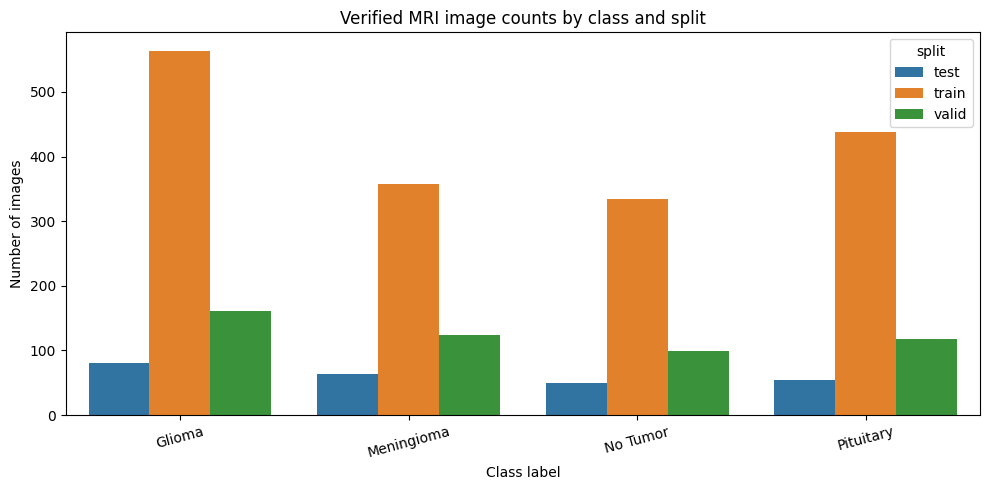

In [7]:
class_counts = (verified_manifest.groupby(['split', 'label']).size()
                .unstack(fill_value=0)
                .reindex(index=SPLITS, columns=CSV_LABEL_COLUMNS, fill_value=0))
class_counts.loc['TOTAL'] = class_counts.sum(axis=0)
display(class_counts)

plot_counts = (verified_manifest.groupby(['split', 'label']).size()
               .rename('images').reset_index())
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_counts, x='label', y='images', hue='split')
plt.title('Verified MRI image counts by class and split')
plt.xlabel('Class label')
plt.ylabel('Number of images')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Step 6 — Inspect image dimensions and channels

This step reads image metadata without resizing or changing the source files. It records original width, height, image mode, and channel count. Grayscale images commonly have one channel (`L`), RGB images have three, and RGBA images have four. These measurements help us decide later whether any preprocessing is needed.


In [8]:
from PIL import Image

MODE_CHANNELS = {'1': 1, 'L': 1, 'LA': 2, 'P': 1, 'RGB': 3, 'RGBA': 4, 'CMYK': 4}
image_properties = []
image_read_errors = []
for row in verified_manifest.itertuples(index=False):
    path = Path(row.filepath)
    try:
        with Image.open(path) as image:
            width, height = image.size
            mode = image.mode
        image_properties.append({
            'filename': row.filename, 'filepath': row.filepath, 'split': row.split,
            'label': row.label, 'width': width, 'height': height, 'mode': mode,
            'channels': MODE_CHANNELS.get(mode), 'file_size_bytes': path.stat().st_size,
        })
    except Exception as error:
        image_read_errors.append({'filepath': str(path), 'error': str(error)})

image_properties_df = pd.DataFrame(image_properties)
print(f'Images inspected: {len(image_properties_df):,}')
print(f'Images that could not be opened: {len(image_read_errors):,}')
if image_read_errors:
    display(pd.DataFrame(image_read_errors).head(20))
display(image_properties_df.groupby(['split', 'label', 'mode']).size()
        .rename('images').reset_index())
display(image_properties_df[['width', 'height', 'channels', 'file_size_bytes']]
        .describe().round(1))


Images inspected: 2,443
Images that could not be opened: 0


,split,label,mode,images
0,test,Glioma,RGB,80
1,test,Meningioma,RGB,63
2,test,No Tumor,RGB,49
3,test,Pituitary,RGB,54
4,train,Glioma,RGB,564
5,train,Meningioma,RGB,358
6,train,No Tumor,RGB,335
7,train,Pituitary,RGB,438
8,valid,Glioma,RGB,161
9,valid,Meningioma,RGB,124


,width,height,channels,file_size_bytes
count,2443.0,2443.0,2443.0,2443.0
mean,640.0,640.0,3.0,31913.7
std,0.0,0.0,0.0,9310.4
min,640.0,640.0,3.0,16839.0
25%,640.0,640.0,3.0,24626.0
50%,640.0,640.0,3.0,30730.0
75%,640.0,640.0,3.0,37589.0
max,640.0,640.0,3.0,124602.0


## Step 7 — View sample images

This grid displays a few verified images per class. It is a visual sanity check for image loading and folder labels, not a medical assessment.


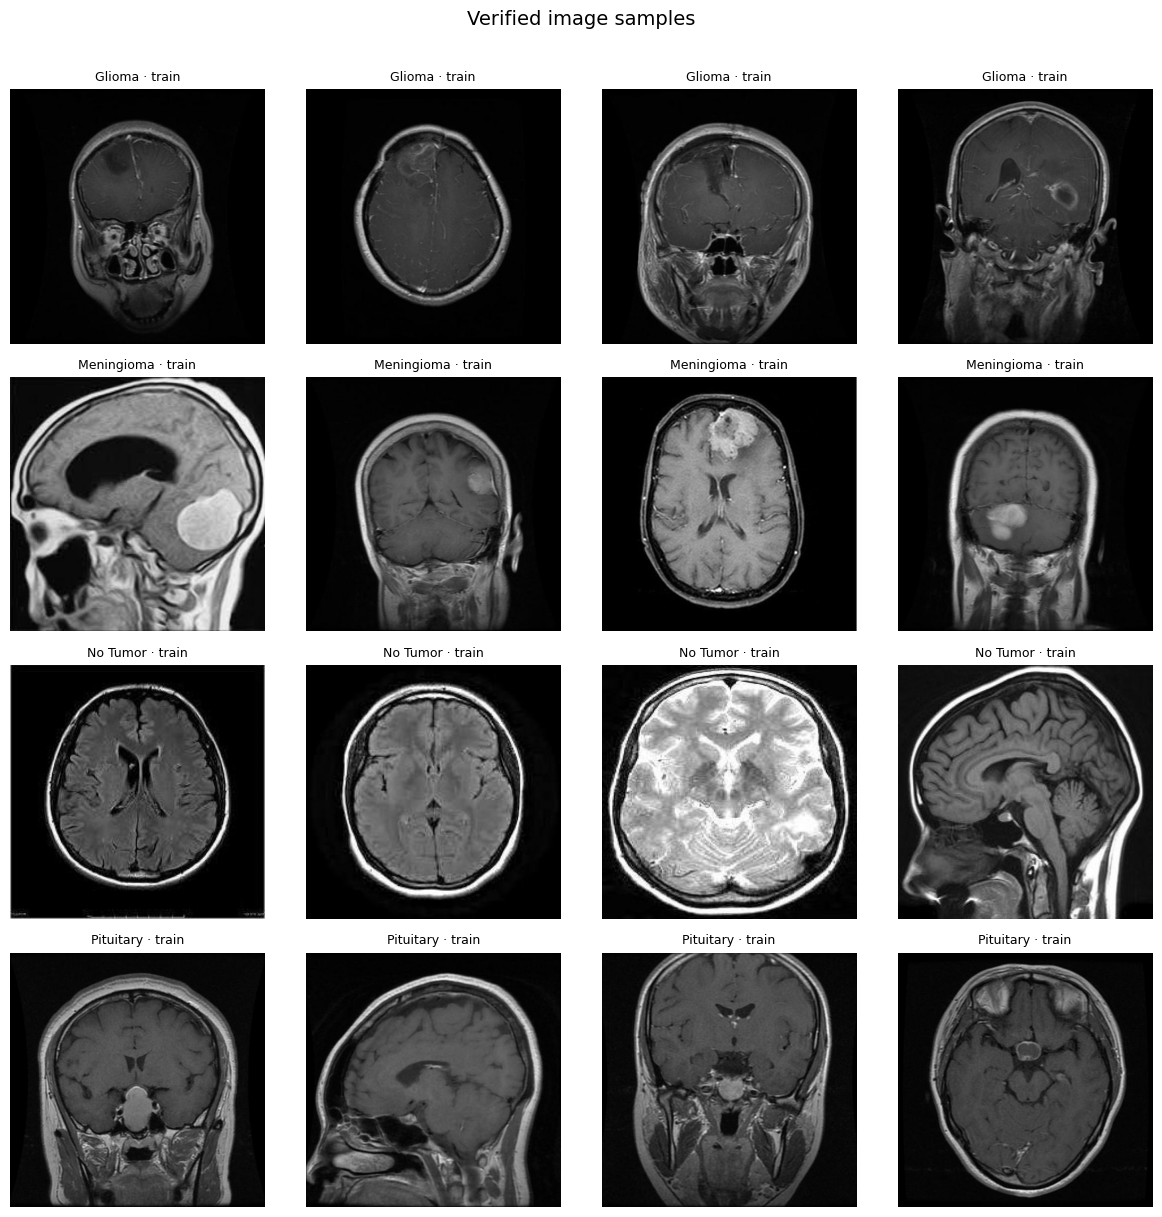

In [9]:
from PIL import Image

fig, axes = plt.subplots(len(CSV_LABEL_COLUMNS), 4, figsize=(12, 3 * len(CSV_LABEL_COLUMNS)))
for row_index, label in enumerate(CSV_LABEL_COLUMNS):
    examples = verified_manifest[verified_manifest['label'] == label].head(4)
    for col_index, ax in enumerate(axes[row_index]):
        ax.axis('off')
        if col_index < len(examples):
            sample = examples.iloc[col_index]
            with Image.open(sample['filepath']) as image:
                ax.imshow(image.convert('RGB'))
            ax.set_title(f"{label} · {sample['split']}", fontsize=9)
plt.suptitle('Verified image samples', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()


## Step 8 — Save the dataset manifest

The master manifest is the organized dataset index: one row per image, with its file path, split, verified class, original one-hot label, and verification status. The original image files stay in their existing folders. We also save the image-property table and any issues so they can be reviewed.


In [10]:
OUTPUT_DIR = DATASET_ROOT.parent / 'notebook_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = OUTPUT_DIR / 'brain_mri_dataset_manifest.csv'
properties_path = OUTPUT_DIR / 'brain_mri_image_properties.csv'
issues_path = OUTPUT_DIR / 'brain_mri_dataset_issues.csv'

manifest_all.to_csv(manifest_path, index=False)
image_properties_df.to_csv(properties_path, index=False)
issues_df.to_csv(issues_path, index=False)

print('Saved manifest:', manifest_path)
print('Saved image properties:', properties_path)
print('Saved issues report:', issues_path)


Saved manifest: /content/drive/MyDrive/Brain MRI Tumor Classification/notebook_outputs/brain_mri_dataset_manifest.csv
Saved image properties: /content/drive/MyDrive/Brain MRI Tumor Classification/notebook_outputs/brain_mri_image_properties.csv
Saved issues report: /content/drive/MyDrive/Brain MRI Tumor Classification/notebook_outputs/brain_mri_dataset_issues.csv


## Notebook 1 complete

At this point, the image collection has a verified manifest and a basic profile of its classes and image properties. We have not resized, normalized, augmented, or otherwise modified the source images. The next notebook can use `brain_mri_dataset_manifest.csv` to load only the training images and apply the preprocessing actually required by the selected model.
